[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/05_linear_regression.ipynb)

# 05 · Linear Regression: The Model Everything Else Builds On

**Part 1 — Classical supervised learning** · Notebook 5 of 27

Part 0 built the tools: linear algebra (01), probability (02), optimization (03) and gradients (04). Now we put them together on the most important model in machine learning. Linear regression is simple enough to solve exactly, and rich enough that almost every idea in this series shows up in it first: likelihoods, loss functions, closed-form vs. iterative solutions, overfitting, regularization, and uncertainty. A single neuron with no activation function *is* linear regression, so everything here carries straight into deep learning.

**What you'll learn**

1. The setup: features, targets and the design matrix
2. The probabilistic model, and why it gives squared error
3. Solving it exactly: the **normal equation**, built from scratch
4. The geometry: least squares is a **projection**
5. Solving it iteratively: gradient descent and SGD, and when to prefer them
6. Real data: interpreting coefficients, $R^2$ and residual plots
7. **Basis functions**: fitting curves with a *linear* model
8. **Ridge regression** = MAP with a Gaussian prior
9. How certain are the coefficients? (sampling variability)
10. Pitfalls: extrapolation, outliers and correlated features

*Course map: CX 4240 Lecture 2 (linear regression via linear algebra), Lecture 4 (optimization for LMS) and Lecture 6 (Supervised Learning: Linear Regression); ISYE 4600 HW1 (housing-price regression) and W6 (polynomial regression).*

In [1]:
#@title ⚙️ Setup — run this cell first (imports, plot style, helpers)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display, Markdown
import ipywidgets as widgets
from ipywidgets import interact, FloatSlider, IntSlider

# One consistent, colorblind-checked palette used across the whole series
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#4a3aa7", red="#e34948",
         ink="#0b0b0b", muted="#52514e", light="#d9d8d3")
plt.rcParams.update({
    "figure.figsize": (6.4, 4.2), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.prop_cycle": plt.cycler(color=[C[k] for k in
        ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]),
    "lines.linewidth": 2, "font.size": 11, "legend.frameon": False,
    "animation.embed_limit": 40, "animation.frame_format": "jpeg",   # JPEG frames keep notebooks small
})

def show_anim(anim):
    """Render a matplotlib animation as an interactive player (play / pause / scrub)."""
    plt.close(anim._fig)
    return HTML(anim.to_jshtml(default_mode="once"))

rng = np.random.default_rng(0)
print("Setup complete ✓")
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
import time
print("Ready ✓")

Setup complete ✓


Ready ✓


---
## 1. The setup: features, targets and the design matrix

We have $m$ training examples. Example $i$ has a **feature vector** $x^i \in \mathbb{R}^d$ (the inputs: living area, number of bedrooms, ...) and a **target** $y^i \in \mathbb{R}$ (the output we want to predict: rent). Linear regression predicts

$$\hat y = \theta_0 + \theta_1 x_1 + \theta_2 x_2 + \dots + \theta_d x_d = \theta^\top x$$

where the last step uses a standard trick: prepend a constant feature $x_0 = 1$ to every example, so the intercept $\theta_0$ is just another weight. From now on $x$ includes that leading 1.

Stack the examples as the **rows** of the **design matrix** $X$ and the targets into a vector $y$:

$$X = \begin{bmatrix} 1 & x^1_1 & \cdots & x^1_d \\ 1 & x^2_1 & \cdots & x^2_d \\ \vdots & & & \vdots \\ 1 & x^m_1 & \cdots & x^m_d \end{bmatrix} \in \mathbb{R}^{m \times (d+1)}, \qquad y = \begin{bmatrix} y^1 \\ \vdots \\ y^m \end{bmatrix}$$

Then all $m$ predictions at once are a single matrix-vector product: $\hat y = X\theta$.

> 🤔 **Question: My CX 4240 slides write $\hat\theta = (XX^\top)^{-1}Xy$, but ISYE 4600 writes $(X^\top X)^{-1}X^\top y$. Which is right?**
>
> Both. It's only a convention about whether examples are **columns** or **rows**. CX 4240 stacks examples as columns, $X = [x^1, \dots, x^m] \in \mathbb{R}^{d \times m}$; ISYE 4600 (and NumPy, scikit-learn, PyTorch) stack them as rows, $X \in \mathbb{R}^{m \times d}$. One is the transpose of the other, so the formulas are the same thing. This series uses **rows**, because that's how data arrives in code: one row per example.

Here are the apartments from notebook 00, now with both features in play:

In [2]:
# Same synthetic Atlanta apartments as notebook 00 (same seed, same "true" rule)
rng = np.random.default_rng(0)
n = 60
area = rng.uniform(300, 1400, n)
bedrooms = np.clip(np.round(area / 450 + rng.normal(0, 0.4, n)), 1, 4)
rent = 500 + 1.4 * area + 100 * bedrooms + rng.normal(0, 150, n)

X = np.column_stack([np.ones(n), area, bedrooms])      # design matrix: [1, area, bedrooms]
y = rent
df = pd.DataFrame(X, columns=["x0 (=1)", "area", "bedrooms"]).assign(rent=y)
print(f"X has shape {X.shape}  (m = {n} examples, d + 1 = {X.shape[1]} columns)")
df.head().round(1)

X has shape (60, 3)  (m = 60 examples, d + 1 = 3 columns)


,x0 (=1),area,bedrooms,rent
0,1.0,1000.7,2.0,2219.1
1,1.0,596.8,1.0,1562.1
2,1.0,345.1,1.0,1094.4
3,1.0,318.2,1.0,831.4
4,1.0,1194.6,3.0,2452.2


---
## 2. The probabilistic model, and why it gives squared error

Why squared error? Notebook 02 derived it; here's the short version, since it's the template for every model in Part 1. CX 4240's pipeline has three steps: **build a probabilistic model → derive the loss by MLE/MAP → pick an optimizer.**

**Step 1, the model.** Assume each target is the linear prediction plus Gaussian noise:

$$y^i = \theta^\top x^i + \epsilon^i, \qquad \epsilon^i \sim \mathcal{N}(0, \sigma^2) \quad\Longleftrightarrow\quad p(y^i \mid x^i; \theta) = \frac{1}{\sqrt{2\pi}\sigma}\exp\!\left(-\frac{(y^i - \theta^\top x^i)^2}{2\sigma^2}\right)$$

So the model doesn't say "rent *is* this line"; it says "rent is **scattered around** this line, in a bell curve of width $\sigma$." The picture below draws those bell curves sideways at a few locations.

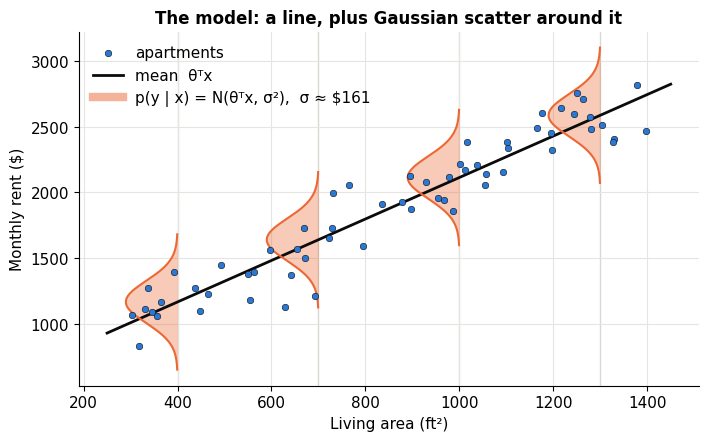

In [3]:
# Visualize p(y | x): a Gaussian bell around the regression line at every x
x1 = area
t0, t1 = np.linalg.lstsq(np.column_stack([np.ones(n), x1]), rent, rcond=None)[0]   # best single-feature line
sigma = np.std(rent - (t0 + t1 * x1))
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.scatter(x1, rent, s=22, color=C["blue"], edgecolor=C["ink"], linewidth=0.4, zorder=3, label="apartments")
xs = np.linspace(250, 1450, 2)
ax.plot(xs, t0 + t1 * xs, color=C["ink"], lw=2, label="mean  θᵀx")
for xc in [400, 700, 1000, 1300]:
    yy = np.linspace(-3.2 * sigma, 3.2 * sigma, 200)
    dens = np.exp(-yy**2 / (2 * sigma**2))
    mu = t0 + t1 * xc
    ax.fill_betweenx(mu + yy, xc, xc - 110 * dens, color=C["orange"], alpha=0.35, lw=0)
    ax.plot(xc - 110 * dens, mu + yy, color=C["orange"], lw=1.5)
    ax.axvline(xc, color=C["light"], lw=1, zorder=0)
ax.plot([], [], color=C["orange"], lw=6, alpha=0.5, label=f"p(y | x) = N(θᵀx, σ²),  σ ≈ ${sigma:.0f}")
ax.set(xlabel="Living area (ft²)", ylabel="Monthly rent ($)", title="The model: a line, plus Gaussian scatter around it")
ax.legend(loc="upper left"); plt.show()

**Step 2, the loss.** The examples are independent, so the likelihood is a product, and the log-likelihood is a sum:

$$\log L(\theta) = \sum_{i=1}^m \log p(y^i \mid x^i;\theta) = -\frac{m}{2}\log(2\pi\sigma^2) \;-\; \frac{1}{2\sigma^2}\sum_{i=1}^m \big(y^i - \theta^\top x^i\big)^2$$

The first term doesn't depend on $\theta$, and the second is a negative constant times the **sum of squared errors**. So

$$\boxed{\;\arg\max_\theta \log L(\theta) \;=\; \arg\min_\theta \; \frac1m \sum_{i=1}^m (y^i - \theta^\top x^i)^2 \;=\; \arg\min_\theta \; \frac1m\|y - X\theta\|^2\;}$$

Maximum likelihood under Gaussian noise **is** least squares. (A different noise model gives a different loss: Laplace noise gives absolute error. Notebook 02, section 11, shows the two side by side with outliers.)

**Step 3, the optimizer.** This loss is special: it can be minimized exactly. That's next.

---
## 3. Solving it exactly: the normal equation

The loss $J(\theta) = \frac1m\|y - X\theta\|^2$ is a convex bowl (notebook 01: its Hessian $\frac2m X^\top X$ is positive semi-definite). Its minimum is where the gradient is zero. Expand and differentiate, using the matrix-calculus rules from notebook 01 ($\nabla_\theta\, b^\top\theta = b$ and $\nabla_\theta\, \theta^\top A \theta = 2A\theta$ for symmetric $A$):

$$J(\theta) = \frac1m\left(y^\top y - 2\,\theta^\top X^\top y + \theta^\top X^\top X\,\theta\right)$$

$$\nabla_\theta J = \frac1m\left(-2X^\top y + 2X^\top X\,\theta\right) = -\frac{2}{m}X^\top\big(y - X\theta\big)$$

Setting it to zero gives the **normal equation**:

$$X^\top X\,\hat\theta = X^\top y \qquad\Longrightarrow\qquad \hat\theta = (X^\top X)^{-1}X^\top y \quad \text{(when } X^\top X \text{ is invertible)}$$

Read the gradient formula carefully: $y - X\theta$ is the vector of **residuals** $r$. So the optimum is where $X^\top r = 0$: the residuals are uncorrelated with every feature, including the constant one (so they average to zero). Hold that thought for section 4.

Let's implement it, without `inv`. Notebook 01 explained why: solving the linear system is faster and more accurate than forming an inverse.

In [4]:
def fit_normal_equation(X, y):
    """Least squares by solving the normal equation  XᵀX θ = Xᵀy."""
    return np.linalg.solve(X.T @ X, X.T @ y)

theta_hat = fit_normal_equation(X, y)
print("Our normal equation:  θ =", theta_hat.round(3))

sk = LinearRegression().fit(X[:, 1:], y)             # sklearn adds the intercept itself
print("scikit-learn:         θ =", np.r_[sk.intercept_, sk.coef_].round(3))
print("np.linalg.lstsq:      θ =", np.linalg.lstsq(X, y, rcond=None)[0].round(3))

r = y - X @ theta_hat
print("\nXᵀr (should be ~0):", (X.T @ r).round(8))
print(f"mean residual = {r.mean():.2e},  training MSE = {np.mean(r**2):,.0f},  RMSE = ${np.sqrt(np.mean(r**2)):.0f}")
print("\nTrue rule was rent = 500 + 1.4·area + 100·bedrooms + noise")

Our normal equation:  θ = [492.749   1.254 161.603]
scikit-learn:         θ = [492.749   1.254 161.603]
np.linalg.lstsq:      θ = [492.749   1.254 161.603]

Xᵀr (should be ~0): [-0.e+00  3.e-08 -0.e+00]
mean residual = -2.07e-13,  training MSE = 20,897,  RMSE = $145

True rule was rent = 500 + 1.4·area + 100·bedrooms + noise


All three agree. The intercept and the area coefficient land close to the true values (500 and 1.4). The bedroom coefficient is further off (about 160 vs. the true 100), because 60 noisy apartments can't pin it down well. Section 9 explains why bedrooms specifically is so uncertain, and measures how uncertain.

Now we can price the two apartments from notebook 00:

In [5]:
new = np.array([[1, 150, 1], [1, 270, 1.5]])
for row, pred in zip(new, new @ theta_hat):
    print(f"area = {row[1]:.0f} ft², bedrooms = {row[2]}:  predicted rent ≈ ${pred:,.0f}")

area = 150 ft², bedrooms = 1.0:  predicted rent ≈ $842
area = 270 ft², bedrooms = 1.5:  predicted rent ≈ $1,074


> 🤔 **Question: Those apartments are smaller than anything in the training data (300–1400 ft²). Should I trust these predictions?**
>
> Less than the in-range ones. This is **extrapolation**: the model has never seen a 150 ft² apartment, and nothing guarantees the straight-line relationship continues down there. Section 10 shows how badly extrapolation can go.

> 🤔 **Question: When is $X^\top X$ not invertible?**
>
> When some feature is an exact linear combination of others (the columns of $X$ are linearly dependent, so $\text{rank}(X) < d+1$), or when there are fewer examples than parameters ($m < d+1$). Example: including both "area in ft²" and "area in m²". Then infinitely many $\theta$ fit equally well. `lstsq` returns the one with the smallest norm (via the SVD, notebook 01), and **ridge regression** (section 8) fixes it by adding $\lambda I$, which makes the matrix invertible for any $\lambda > 0$.

---
## 4. The geometry: least squares is a projection

Here's the picture from CX 4240 Lecture 6. Think of $y$ as a single point in $\mathbb{R}^m$ (one coordinate per training example). Every possible prediction $X\theta$ is a combination of the columns of $X$, so all predictions together form a flat subspace: the **column space** of $X$. Least squares picks the point $\hat y = X\hat\theta$ in that subspace **closest** to $y$.

The closest point in a plane is the **orthogonal projection**: you drop a perpendicular. That's exactly the condition $X^\top r = 0$ we found above: the residual vector $r = y - \hat y$ is perpendicular to every column of $X$, hence to the whole plane.

With $m = 3$ examples and 2 columns, we can actually draw it:

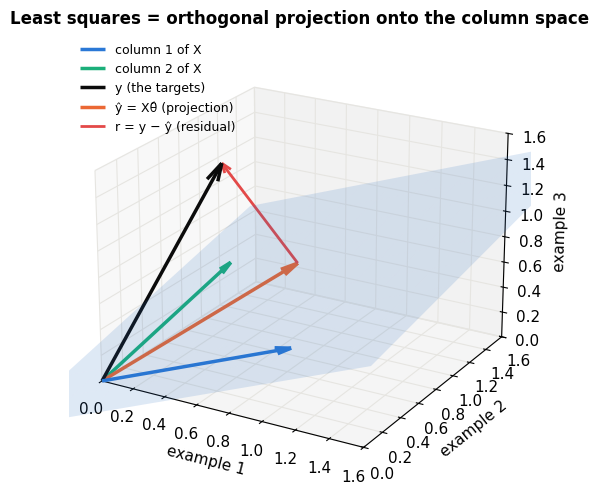

r · column1 = 0.0    r · column2 = 0.0


In [6]:
# 3 examples, 2 features (no intercept), so everything lives in R^3 and the column space is a plane
X3 = np.array([[1.0, 0.2], [0.3, 1.0], [0.4, 0.5]])
y3 = np.array([0.4, 0.6, 1.5])
th3 = np.linalg.solve(X3.T @ X3, X3.T @ y3)
yhat3 = X3 @ th3; r3 = y3 - yhat3

def plot_projection(elev=22, azim=-60):
    fig = plt.figure(figsize=(7, 6)); ax = fig.add_subplot(111, projection="3d")
    s = np.linspace(-0.3, 1.6, 10); S, T = np.meshgrid(s, s)
    P = S[..., None] * X3[:, 0] + T[..., None] * X3[:, 1]
    ax.plot_surface(P[..., 0], P[..., 1], P[..., 2], color=C["blue"], alpha=0.15, linewidth=0)
    def arrow(v, start=np.zeros(3), color=C["ink"], label=None, lw=2.5):
        ax.quiver(*start, *v, color=color, lw=lw, arrow_length_ratio=0.08, label=label)
    arrow(X3[:, 0], color=C["blue"], label="column 1 of X")
    arrow(X3[:, 1], color=C["aqua"], label="column 2 of X")
    arrow(y3, color=C["ink"], label="y (the targets)")
    arrow(yhat3, color=C["orange"], label="ŷ = Xθ̂ (projection)")
    arrow(r3, start=yhat3, color=C["red"], label="r = y − ŷ (residual)", lw=2)
    ax.set(xlabel="example 1", ylabel="example 2", zlabel="example 3", xlim=(0, 1.6), ylim=(0, 1.6), zlim=(0, 1.6))
    ax.view_init(elev=elev, azim=azim); ax.legend(loc="upper left", fontsize=9)
    ax.set_title("Least squares = orthogonal projection onto the column space")
    plt.show()

plot_projection()
print("r · column1 =", round(r3 @ X3[:, 0], 12), "   r · column2 =", round(r3 @ X3[:, 1], 12))

🎚️ **Rotate the view** to convince yourself the red residual meets the blue plane at a right angle.

In [7]:
interact(plot_projection, elev=IntSlider(value=22, min=-10, max=90, step=4, description="elevation"),
         azim=IntSlider(value=-60, min=-180, max=180, step=10, description="azimuth"));

The projection view explains several facts at once:

- **The hat matrix.** $\hat y = X(X^\top X)^{-1}X^\top y = Hy$. The matrix $H$ is a projection: applying it twice changes nothing ($H^2 = H$).
- **Adding a feature never increases training error.** It enlarges the subspace, and the closest point in a bigger subspace can only be closer. That's why training error alone can't tell you whether a feature is useful (notebook 06).
- **Pythagoras.** $\|y\|^2 = \|\hat y\|^2 + \|r\|^2$. With an intercept, the same holds after centering, which is where $R^2$ comes from (section 6).

In [8]:
H = X @ np.linalg.solve(X.T @ X, X.T)                 # the hat matrix for the apartment data
print("H is m x m:", H.shape, "  ‖H² − H‖ =", np.abs(H @ H - H).max().round(12), "  trace(H) =", np.trace(H).round(6), "= number of parameters")
yc, yhc, rc = y - y.mean(), X @ theta_hat - y.mean(), y - X @ theta_hat
print(f"Pythagoras (centered):  ‖y−ȳ‖² = {yc@yc:,.0f}   ‖ŷ−ȳ‖² + ‖r‖² = {yhc@yhc + rc@rc:,.0f}")

H is m x m: (60, 60)   ‖H² − H‖ = 0.0   trace(H) = 3.0 = number of parameters
Pythagoras (centered):  ‖y−ȳ‖² = 17,445,512   ‖ŷ−ȳ‖² + ‖r‖² = 17,445,512


---
## 5. Solving it iteratively: gradient descent and SGD

The normal equation needs $X^\top X$, a $(d+1)\times(d+1)$ matrix, and a solve that costs $O(d^3)$. That's instant for $d = 3$, but with a million features (common for text) it's hopeless, and with a billion examples you can't even hold $X$ in memory. Then we fall back on notebook 03's tools. The gradient is the one we derived:

$$\nabla J(\theta) = -\frac{2}{m}X^\top (y - X\theta) \qquad\Longrightarrow\qquad \theta \leftarrow \theta + \eta\,\frac{2}{m}\sum_{i=1}^m \big(y^i - \theta^\top x^i\big)\,x^i$$

Read the update in words: **for each example, nudge $\theta$ in the direction of $x^i$, by an amount proportional to how wrong the prediction was.** Under-predicted rent ($y > \hat y$)? Move $\theta$ to increase the prediction. This is the **least-mean-squares (LMS)** rule from CX 4240 Lectures 4 and 6. SGD uses one example (or a small batch) per step instead of all $m$.

Let's watch both learn. We standardize the features first (notebook 03 showed why: otherwise the bowl is a ravine and GD crawls).

In [9]:
mu_f, sd_f = X[:, 1:].mean(0), X[:, 1:].std(0)
Xs = np.column_stack([np.ones(n), (X[:, 1:] - mu_f) / sd_f])     # standardized design matrix
theta_star = fit_normal_equation(Xs, y)

def run_gd(Xm, y, lr, steps, batch=None, seed=0):
    r_ = np.random.default_rng(seed)
    th = np.zeros(Xm.shape[1]); path = [th.copy()]
    for _ in range(steps):
        idx = r_.choice(len(y), batch, replace=False) if batch else slice(None)
        Xb, yb = Xm[idx], y[idx]
        th = th + lr * 2 / len(yb) * Xb.T @ (yb - Xb @ th)
        path.append(th.copy())
    return np.array(path)

gd_path = run_gd(Xs, y, lr=0.1, steps=60)
sgd_path = run_gd(Xs, y, lr=0.05, steps=60, batch=4)
mse = lambda th: np.mean((y - Xs @ th) ** 2)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.3), dpi=72)
order = np.argsort(area)
ax1.scatter(area, y, s=18, color=C["blue"], edgecolor=C["ink"], linewidth=0.3)
line_gd, = ax1.plot([], [], color=C["red"], lw=2, label="GD (full batch)")
line_sgd, = ax1.plot([], [], color=C["aqua"], lw=2, label="SGD (batch of 4)")
ax1.set(xlabel="Living area (ft²)", ylabel="rent ($)", ylim=(0, 3200)); ax1.legend(loc="upper left")
ax2.axhline(mse(theta_star), color=C["ink"], ls="--", lw=1, label="normal equation (exact)")
c_gd, = ax2.semilogy([], [], color=C["red"], label="GD"); c_sgd, = ax2.semilogy([], [], color=C["aqua"], label="SGD")
ax2.set(xlim=(0, 60), ylim=(1e4, 5e6), xlabel="step", ylabel="training MSE (log)"); ax2.legend()
title = ax1.set_title(""); fig.tight_layout()

def frame(k):
    # plot predictions vs. area, sorted, so the (bedroom-dependent) fit shows as a jagged line
    line_gd.set_data(area[order], (Xs @ gd_path[k])[order]); line_sgd.set_data(area[order], (Xs @ sgd_path[k])[order])
    c_gd.set_data(range(k + 1), [mse(t) for t in gd_path[:k + 1]]); c_sgd.set_data(range(k + 1), [mse(t) for t in sgd_path[:k + 1]])
    title.set_text(f"step {k}")
    return line_gd, line_sgd, c_gd, c_sgd

show_anim(animation.FuncAnimation(fig, frame, frames=range(0, 61, 2), interval=150))

(The fitted "line" looks jagged because predictions also depend on bedrooms, which jump between integers.)

Both converge to the exact answer. SGD is noisier, but each of its steps looked at 4 apartments instead of 60. Which method should you use?

| Method | Cost | Use when |
|---|---|---|
| Normal equation (`solve`) | $O(md^2 + d^3)$, one shot | $d$ up to a few thousand; you want the exact answer |
| QR / SVD (`lstsq`) | a bit more, but numerically safer | features are nearly collinear |
| Gradient descent | $O(md)$ per step, many steps | $d$ large, data fits in memory |
| SGD / mini-batch | $O(bd)$ per step | huge $m$, streaming data, or the model isn't linear (every neural network) |

Here's the crossover, measured:

In [10]:
def timing(m, d, reps=3):
    r_ = np.random.default_rng(1)
    Xt = r_.normal(size=(m, d)); yt = Xt @ r_.normal(size=d) + r_.normal(size=m)
    t0 = time.perf_counter()
    for _ in range(reps): np.linalg.solve(Xt.T @ Xt, Xt.T @ yt)
    t_ne = (time.perf_counter() - t0) / reps
    t0 = time.perf_counter()
    th = np.zeros(d)
    for _ in range(20): th += 0.1 / m * Xt.T @ (yt - Xt @ th)      # 20 GD steps
    t_gd = (time.perf_counter() - t0)
    return t_ne, t_gd

print(f"{'m':>7} {'d':>6} | normal eq. (s) | 20 GD steps (s)")
for m_, d_ in [(5000, 50), (5000, 500), (5000, 2000), (5000, 4000)]:
    a_, b_ = timing(m_, d_)
    print(f"{m_:>7} {d_:>6} | {a_:14.4f} | {b_:14.4f}")

      m      d | normal eq. (s) | 20 GD steps (s)
   5000     50 |         0.0007 |         0.0072
   5000    500 |         0.0183 |         0.0658


   5000   2000 |         0.2355 |         0.3516


   5000   4000 |         1.0097 |         0.9474


With 50 features the exact solve is 10× faster than even 20 gradient steps. By a few thousand features the two cost about the same, and the exact solve's cost keeps growing like $d^3$ (and its memory like $d^2$: with 100,000 features, $X^\top X$ alone is 80 GB). Gradient methods grow only linearly in $d$, which is why everything in Part 3 (deep learning) trains with SGD.

---
## 6. Real data: interpreting coefficients, $R^2$ and residual plots

Time for real data. scikit-learn ships the **diabetes** dataset: 442 patients, 10 baseline measurements, and a target measuring disease progression one year later. (It comes with the library, so no download is needed.)

In [11]:
data = load_diabetes(scaled=False, as_frame=True)
D = data.frame
names = {"age": "age", "sex": "sex", "bmi": "body-mass index", "bp": "blood pressure",
         "s1": "total cholesterol", "s2": "LDL", "s3": "HDL", "s4": "chol./HDL ratio", "s5": "log triglycerides", "s6": "blood sugar"}
print(D.shape); D.describe().T[["mean", "std", "min", "max"]].round(2)

(442, 11)


,mean,std,min,max
age,48.52,13.11,19.00,79.00
sex,1.47,0.50,1.00,2.00
bmi,26.38,4.42,18.00,42.20
bp,94.65,13.83,62.00,133.00
s1,189.14,34.61,97.00,301.00
s2,115.44,30.41,41.60,242.40
s3,49.79,12.93,22.00,99.00
s4,4.07,1.29,2.00,9.09
s5,4.64,0.52,3.26,6.11
s6,91.26,11.50,58.00,124.00


Always hold out a **test set** before fitting anything. The model never sees it during training, so it gives an honest estimate of performance on new patients (notebook 06 goes much deeper on this).

The usual summary of fit quality is the **coefficient of determination**:

$$R^2 = 1 - \frac{\sum_i (y^i - \hat y^i)^2}{\sum_i (y^i - \bar y)^2} = 1 - \frac{\text{MSE of the model}}{\text{MSE of always predicting the mean}}$$

$R^2 = 1$ is perfect, $R^2 = 0$ is no better than predicting the average, and on test data it can even be negative.

train R² = 0.555   test R² = 0.359
test RMSE = 56.4   (the target's std is 70.5)


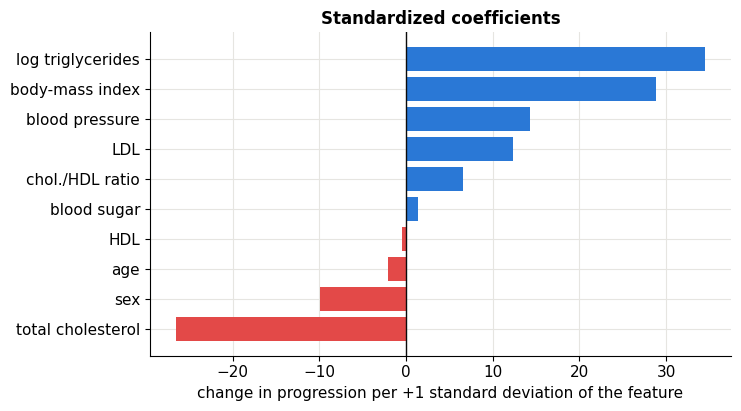

In [12]:
Xd, yd = D[data.feature_names].values, D["target"].values
Xtr, Xte, ytr, yte = train_test_split(Xd, yd, test_size=0.25, random_state=0)

# Standardize using TRAINING statistics only (using test statistics would leak information)
mu_d, sd_d = Xtr.mean(0), Xtr.std(0)
Z = lambda A: (A - mu_d) / sd_d
add1 = lambda A: np.column_stack([np.ones(len(A)), A])
th_d = fit_normal_equation(add1(Z(Xtr)), ytr)

def r2(y_true, y_pred):
    return 1 - np.sum((y_true - y_pred) ** 2) / np.sum((y_true - y_true.mean()) ** 2)

pred_tr, pred_te = add1(Z(Xtr)) @ th_d, add1(Z(Xte)) @ th_d
print(f"train R² = {r2(ytr, pred_tr):.3f}   test R² = {r2(yte, pred_te):.3f}")
print(f"test RMSE = {np.sqrt(np.mean((yte - pred_te)**2)):.1f}   (the target's std is {yte.std():.1f})")

fig, ax = plt.subplots(figsize=(7.5, 4.2))
coefs = pd.Series(th_d[1:], index=[names[f] for f in data.feature_names]).sort_values()
ax.barh(coefs.index, coefs.values, color=[C["red"] if v < 0 else C["blue"] for v in coefs.values])
ax.axvline(0, color=C["ink"], lw=1)
ax.set(xlabel="change in progression per +1 standard deviation of the feature", title="Standardized coefficients")
plt.show()

Because the features were standardized, each coefficient means "how much the prediction changes when this feature goes up by one standard deviation, **holding all the others fixed**." That makes them comparable: body-mass index and log triglycerides matter most.

Two cautions when reading coefficients:

- **"Holding all others fixed" can be impossible.** Total cholesterol and LDL are strongly correlated (LDL is part of total cholesterol), so their coefficients come out with opposite signs: total cholesterol looks strongly *protective* and LDL harmful, and the two partly cancel. Neither number means much on its own. Section 10 shows this instability directly.
- **Coefficients are associations, not causes.** The data is observational. A positive coefficient doesn't mean raising that feature *causes* progression.

### Residual plots: is the model's assumption reasonable?

The Gaussian model says residuals should look like **structureless noise**: centered at zero, the same spread everywhere, no curves. Plot residuals against predictions and look for patterns:

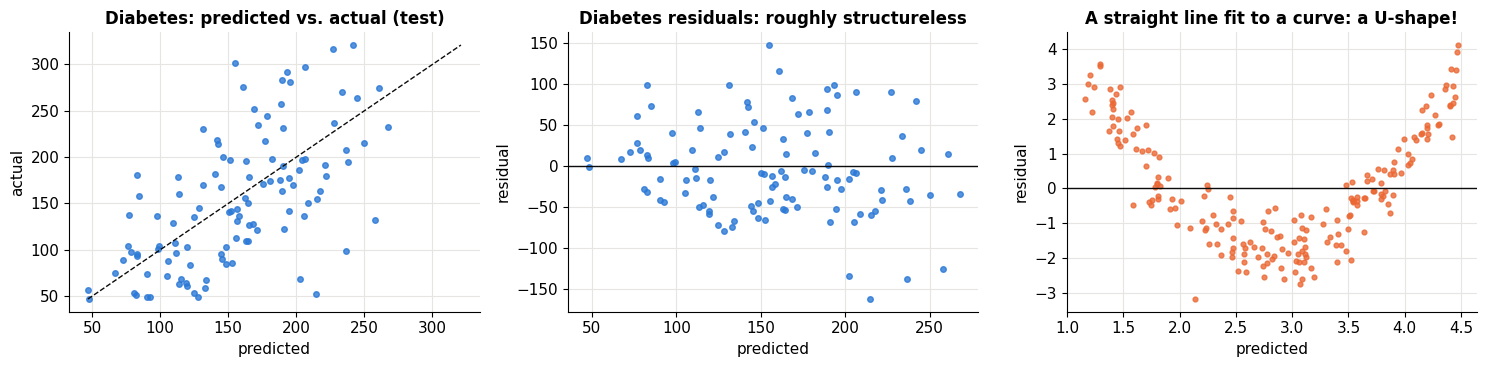

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].scatter(pred_te, yte, s=16, color=C["blue"], alpha=0.8)
lim = [min(pred_te.min(), yte.min()), max(pred_te.max(), yte.max())]
axes[0].plot(lim, lim, color=C["ink"], ls="--", lw=1); axes[0].set(xlabel="predicted", ylabel="actual", title="Diabetes: predicted vs. actual (test)")
axes[1].scatter(pred_te, yte - pred_te, s=16, color=C["blue"], alpha=0.8); axes[1].axhline(0, color=C["ink"], lw=1)
axes[1].set(xlabel="predicted", ylabel="residual", title="Diabetes residuals: roughly structureless")

# A deliberately WRONG model, to show what a bad residual plot looks like
xq = rng.uniform(-3, 3, 200); yq = 1 + 0.5 * xq + 0.6 * xq**2 + rng.normal(0, 0.6, 200)
Aq = add1(xq); tq = fit_normal_equation(Aq, yq)
axes[2].scatter(Aq @ tq, yq - Aq @ tq, s=12, color=C["orange"], alpha=0.8); axes[2].axhline(0, color=C["ink"], lw=1)
axes[2].set(xlabel="predicted", ylabel="residual", title="A straight line fit to a curve: a U-shape!")
fig.tight_layout(); plt.show()

The right panel is what a **misspecified** model looks like: the residuals have a clear U-shape, because the true relationship is curved. The fix is the subject of the next section.

> 🤔 **Question: A test $R^2$ of about 0.36 seems low. Is the model bad?**
>
> It's about as good as it gets with these 10 baseline measurements. Disease progression depends on many things that weren't measured. A low $R^2$ means "lots of unexplained variation", not "the method failed." Try a fancier model (trees, boosting, neural networks) later in the series on this same dataset: none will do dramatically better, because the missing information isn't in the features. (Exercise 4 at the end.)

---
## 7. Basis functions: fitting curves with a *linear* model

"Linear" regression means linear in the **parameters** $\theta$, not in the inputs. We're free to transform the inputs first with any fixed functions $\phi_j(x)$, called **basis functions** or **features**:

$$\hat y = \theta_0 + \theta_1\phi_1(x) + \dots + \theta_p\phi_p(x) = \theta^\top \phi(x)$$

The design matrix just gets new columns, $\Phi_{ij} = \phi_j(x^i)$, and **everything above still works unchanged**: same normal equation, same projection picture. The most common choice is polynomials, $\phi_j(x) = x^j$.

Here's the classic experiment from CX 4240 Lecture 6 (originally from Bishop's textbook): 10 noisy samples of $\sin(2\pi x)$, fit with polynomials of degree $d = 0, 1, 3, 9$.

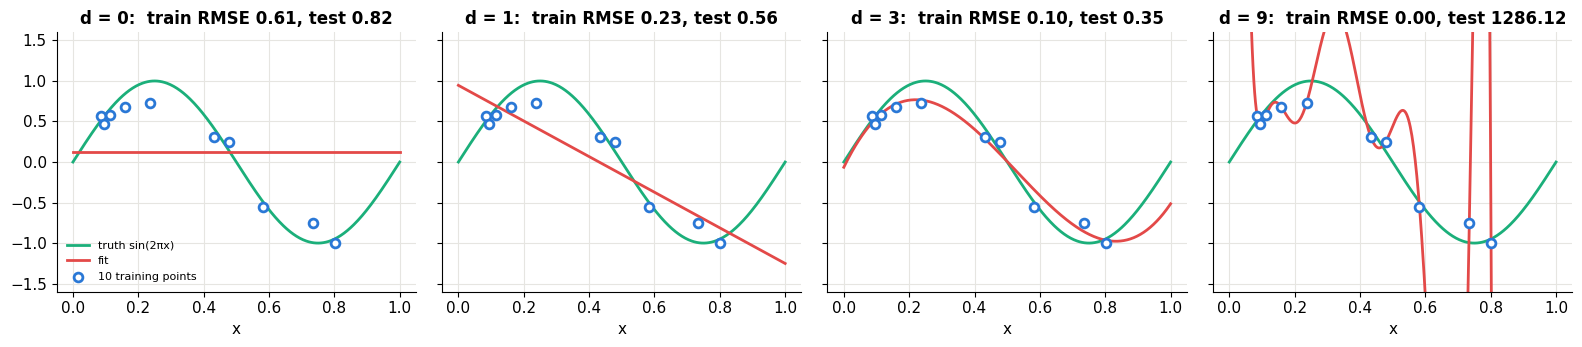

In [14]:
def make_sin_data(m, seed):
    r_ = np.random.default_rng(seed)
    x_ = np.sort(r_.uniform(0, 1, m))
    return x_, np.sin(2 * np.pi * x_) + r_.normal(0, 0.25, m)

poly = lambda x_, d: np.vander(x_, d + 1, increasing=True)     # columns 1, x, x², ..., x^d
xtr_s, ytr_s = make_sin_data(10, seed=3)
xte_s, yte_s = make_sin_data(200, seed=99)
xx = np.linspace(0, 1, 400)

fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharey=True)
for ax, d in zip(axes, [0, 1, 3, 9]):
    th = np.linalg.lstsq(poly(xtr_s, d), ytr_s, rcond=None)[0]
    tr = np.sqrt(np.mean((poly(xtr_s, d) @ th - ytr_s) ** 2)); te = np.sqrt(np.mean((poly(xte_s, d) @ th - yte_s) ** 2))
    ax.plot(xx, np.sin(2 * np.pi * xx), color=C["aqua"], lw=2, label="truth sin(2πx)")
    ax.plot(xx, poly(xx, d) @ th, color=C["red"], lw=2, label="fit")
    ax.scatter(xtr_s, ytr_s, s=40, facecolor="white", edgecolor=C["blue"], lw=2, zorder=3, label="10 training points")
    ax.set(ylim=(-1.6, 1.6), title=f"d = {d}:  train RMSE {tr:.2f}, test {te:.2f}", xlabel="x")
axes[0].legend(loc="lower left", fontsize=8); fig.tight_layout(); plt.show()

- $d = 0, 1$: **underfitting**. Too simple to bend; both training and test error are high.
- $d = 3$: about right. It captures the wave.
- $d = 9$: **overfitting**. Ten parameters, ten points: it passes through every training point exactly (training error 0), and swings wildly in between, so test error explodes.

🎚️ **Change the degree and the number of training points.** Notice that with more data, even high degrees behave: overfitting is about complexity *relative to* the amount of data.

In [15]:
def plot_poly_fit(degree=3, m=10, seed=3):
    xt, yt = make_sin_data(m, seed)
    Phi = poly(xt, degree)
    th = np.linalg.lstsq(Phi, yt, rcond=None)[0]
    tr = np.sqrt(np.mean((Phi @ th - yt) ** 2)); te = np.sqrt(np.mean((poly(xte_s, degree) @ th - yte_s) ** 2))
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw=dict(width_ratios=[1.6, 1]))
    ax1.plot(xx, np.sin(2 * np.pi * xx), color=C["aqua"], lw=2)
    ax1.plot(xx, poly(xx, degree) @ th, color=C["red"], lw=2)
    ax1.scatter(xt, yt, s=36, facecolor="white", edgecolor=C["blue"], lw=2, zorder=3)
    ax1.set(ylim=(-2, 2), title=f"degree {degree}, m = {m}:  train RMSE {tr:.2f},  test RMSE {te:.2f}")
    ax2.bar(range(degree + 1), np.abs(th) + 1e-3, color=C["orange"]); ax2.set_yscale("log")
    ax2.set(xlabel="coefficient index j (of x^j)", ylabel="|θⱼ| (log)", title="coefficient sizes")
    fig.tight_layout(); plt.show()

interact(plot_poly_fit, degree=IntSlider(value=3, min=0, max=12, description="degree"),
         m=IntSlider(value=10, min=5, max=100, step=5, description="# points"),
         seed=IntSlider(value=3, min=0, max=20, description="data seed"));

Look at the right panel at degree 9 with 10 points: the coefficients are in the **thousands or more**. That's the same table as in CX 4240 Lecture 6. To pass exactly through every noisy point, the polynomial uses huge positive and negative terms that nearly cancel. That observation is the whole motivation for the next section: **penalize large coefficients.**

Polynomials aren't the only option. **Gaussian radial basis functions** place a bump at each of several centers, $\phi_j(x) = \exp\!\big(-(x - c_j)^2 / 2s^2\big)$. The fit is a weighted sum of bumps:

In [16]:
centers = np.linspace(0, 1, 9)
rbf = lambda x_, s: np.column_stack([np.ones_like(x_)] + [np.exp(-(x_ - c) ** 2 / (2 * s ** 2)) for c in centers])

def plot_rbf(width=0.1):
    xt, yt = make_sin_data(25, seed=4)
    th = np.linalg.lstsq(rbf(xt, width), yt, rcond=None)[0]
    fig, ax = plt.subplots(figsize=(9, 3.8))
    Phi_xx = rbf(xx, width)
    for j in range(1, len(centers) + 1):
        ax.plot(xx, th[j] * Phi_xx[:, j], color=C["light"], lw=1.2)
    ax.plot(xx, Phi_xx @ th, color=C["red"], lw=2.5, label="fit = sum of weighted bumps")
    ax.plot(xx, np.sin(2 * np.pi * xx), color=C["aqua"], lw=2, label="truth")
    ax.scatter(xt, yt, s=30, facecolor="white", edgecolor=C["blue"], lw=1.5, zorder=3)
    ax.set(ylim=(-2.5, 2.5), title=f"9 Gaussian bumps of width s = {width:.2f}"); ax.legend(loc="lower left", fontsize=9)
    plt.show()

interact(plot_rbf, width=FloatSlider(value=0.1, min=0.02, max=0.5, step=0.01, description="bump width s"));

Narrow bumps give a wiggly, overfit curve; very wide bumps all look alike and the fit gets stiff (and numerically unstable). Notice the pattern: **any fixed set of basis functions turns a nonlinear problem into linear regression.** The catch is that you have to choose the basis by hand. Neural networks (Part 3) *learn* their basis functions instead: the hidden layer is a learned $\phi(x)$, and the last layer is linear regression on top of it.

---
## 8. Ridge regression = MAP with a Gaussian prior

Overfitting showed up as huge coefficients. Notebook 02 (section 10) gave us the tool to discourage them: a **prior**. Put a zero-mean Gaussian prior on the weights, $p(\theta) \propto \exp(-\lambda'\|\theta\|^2)$, which says "I believe the coefficients are probably small." The MAP estimate maximizes $\log L(\theta) + \log p(\theta)$, which is the same as minimizing

$$J_\lambda(\theta) = \frac1m\|y - X\theta\|^2 + \lambda\|\theta\|^2$$

This is **ridge regression**. The gradient picks up one extra term, $2\lambda\theta$, and setting it to zero gives a closed form again:

$$-\frac2m X^\top(y - X\theta) + 2\lambda\theta = 0 \quad\Longrightarrow\quad \hat\theta_{\text{ridge}} = (X^\top X + \lambda m\, I)^{-1}X^\top y$$

(That's CX 4240's $(XX^\top + \lambda m I)^{-1}Xy$ in row convention. Libraries like scikit-learn drop the $\frac1m$ in front of the loss, so their $\alpha$ equals our $\lambda m$.)

Three things happened:
1. **Coefficients shrink** toward zero, by more as $\lambda$ grows.
2. **The matrix is always invertible**: $X^\top X$ is PSD and adding $\lambda m I$ pushes every eigenvalue up by $\lambda m > 0$ (notebook 01). Collinear features and $m < d$ are no longer a problem.
3. In practice, we **don't penalize the intercept** $\theta_0$: shrinking the overall average level of $y$ toward zero makes no sense. We handle that by centering $y$ (or by putting a 0 in the first diagonal entry of $I$).

In [17]:
def fit_ridge(Phi, y, lam):
    """Ridge with an unpenalized intercept (column 0)."""
    m_, p_ = Phi.shape
    P = lam * m_ * np.eye(p_); P[0, 0] = 0.0
    return np.linalg.solve(Phi.T @ Phi + P, Phi.T @ y)

# Check against scikit-learn (alpha = λm, intercept unpenalized)
Phi9 = poly(xtr_s, 9)
lam = 1e-3
ours = fit_ridge(Phi9, ytr_s, lam)
skr = Ridge(alpha=lam * len(ytr_s)).fit(Phi9[:, 1:], ytr_s)
print("max |ours − sklearn| =", np.abs(ours - np.r_[skr.intercept_, skr.coef_]).max().round(8))

max |ours − sklearn| = 0.0


🎚️ **Turn up $\lambda$ on the degree-9 polynomial.** Watch the coefficients collapse from thousands to single digits, and the wild curve calm down into the sine wave. Too much $\lambda$ and it flattens into underfitting.

In [18]:
def plot_ridge(log10_lam=-8.0):
    lam = 10 ** log10_lam
    th = fit_ridge(Phi9, ytr_s, lam)
    tr = np.sqrt(np.mean((Phi9 @ th - ytr_s) ** 2)); te = np.sqrt(np.mean((poly(xte_s, 9) @ th - yte_s) ** 2))
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw=dict(width_ratios=[1.6, 1]))
    ax1.plot(xx, np.sin(2 * np.pi * xx), color=C["aqua"], lw=2)
    ax1.plot(xx, poly(xx, 9) @ th, color=C["red"], lw=2)
    ax1.scatter(xtr_s, ytr_s, s=40, facecolor="white", edgecolor=C["blue"], lw=2, zorder=3)
    ax1.set(ylim=(-2, 2), title=f"degree 9, λ = 1e{log10_lam:.1f}:  train RMSE {tr:.2f},  test RMSE {te:.2f}")
    ax2.bar(range(10), np.abs(th) + 1e-4, color=C["orange"]); ax2.set_yscale("log"); ax2.set_ylim(1e-4, 1e7)
    ax2.set(xlabel="j", ylabel="|θⱼ| (log)", title=f"‖θ‖ = {np.linalg.norm(th[1:]):,.1f}")
    fig.tight_layout(); plt.show()

interact(plot_ridge, log10_lam=FloatSlider(value=-9, min=-9, max=1, step=0.25, description="log₁₀ λ"));

The **regularization path** shows every coefficient as $\lambda$ sweeps from tiny to huge. Each line is one $\theta_j$:

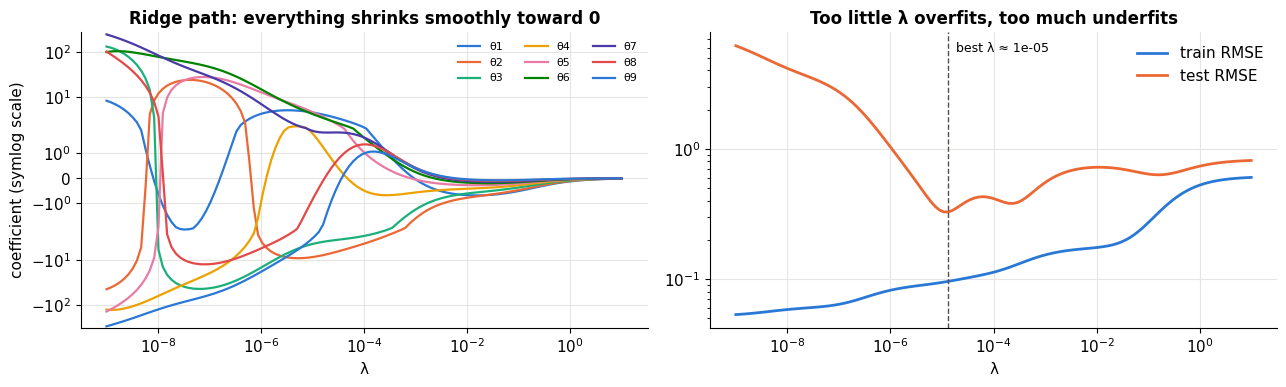

In [19]:
lams = np.logspace(-9, 1, 120)     # below ~1e-9 the degree-9 fit is numerically unstable
path = np.array([fit_ridge(Phi9, ytr_s, l) for l in lams])
te_err = [np.sqrt(np.mean((poly(xte_s, 9) @ t - yte_s) ** 2)) for t in path]
tr_err = [np.sqrt(np.mean((Phi9 @ t - ytr_s) ** 2)) for t in path]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
for j in range(1, 10):
    ax1.plot(lams, path[:, j], lw=1.6, label=f"θ{j}")
ax1.set(xscale="log", yscale="symlog", xlabel="λ", ylabel="coefficient (symlog scale)", title="Ridge path: everything shrinks smoothly toward 0")
ax1.legend(ncol=3, fontsize=8)
ax2.plot(lams, tr_err, color=C["blue"], label="train RMSE"); ax2.plot(lams, te_err, color=C["orange"], label="test RMSE")
best = lams[np.argmin(te_err)]
ax2.axvline(best, color=C["muted"], ls="--", lw=1); ax2.text(best, max(te_err) * 0.9, f"  best λ ≈ {best:.0e}", fontsize=9)
ax2.set(xscale="log", yscale="log", xlabel="λ", title="Too little λ overfits, too much underfits"); ax2.legend()
fig.tight_layout(); plt.show()

The test curve is U-shaped: there's a sweet spot for $\lambda$. Here we cheated by choosing it with the test set. Doing that for real **leaks** test information into the model; the honest way to pick $\lambda$ is **cross-validation**, the main topic of notebook 06.

> 🤔 **Question: Ridge shrinks coefficients toward zero but never exactly to zero. Is there a version that sets some to exactly zero?**
>
> Yes: replace the Gaussian prior with a **Laplace** prior, which turns the penalty $\|\theta\|_2^2$ into $\|\theta\|_1$. That's the **Lasso**, and it does automatic feature selection. The geometric reason (the $\ell_1$ ball has corners) appeared in notebooks 01 and 03; notebook 07 builds the Lasso from scratch.

> 🤔 **Question: Do I need to standardize features before ridge?**
>
> Yes. The penalty $\lambda\sum_j\theta_j^2$ treats all coefficients equally, but a coefficient's size depends on its feature's units. Area in ft² gets a tiny coefficient, area in thousands of ft² a large one. Without standardizing, ridge would mostly shrink whichever features happen to have small units. (Plain least squares doesn't care about units; regularized regression does.)

---
## 9. How certain are the coefficients?

Our apartment fit gave $\hat\theta \approx$ (base, $/ft², $/bedroom) close to the truth (500, 1.4, 100), but different. If we collected a **different** 60 apartments, we'd get different estimates. How much would they move?

Simulate it: draw many fresh datasets from the same "true" rule, fit each one, and look at the spread.

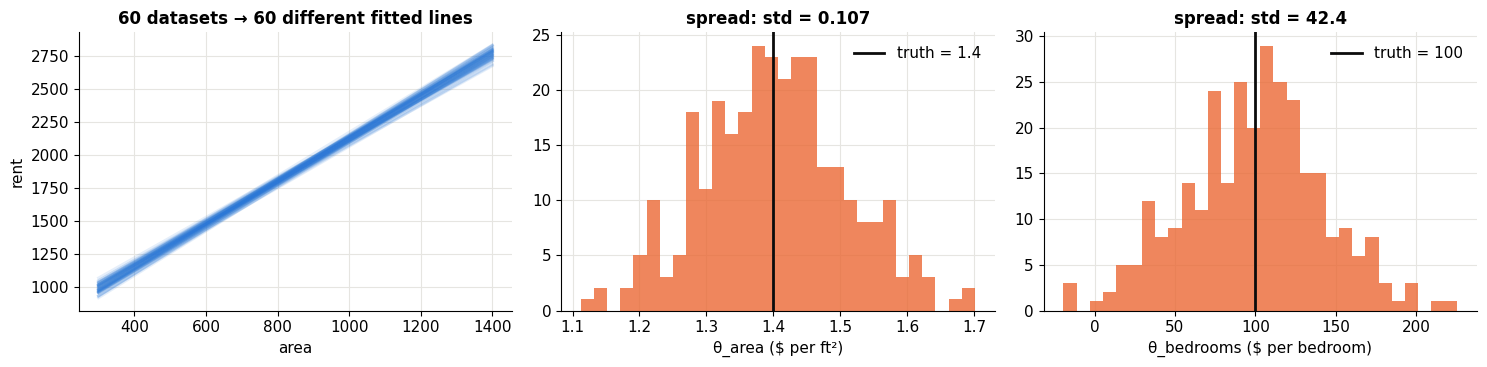

In [20]:
def simulate_fits(n_datasets=300, m=60, seed=1):
    r_ = np.random.default_rng(seed)
    thetas, lines = [], []
    for _ in range(n_datasets):
        a = r_.uniform(300, 1400, m); b = np.clip(np.round(a / 450 + r_.normal(0, 0.4, m)), 1, 4)
        yy_ = 500 + 1.4 * a + 100 * b + r_.normal(0, 150, m)
        Xm = np.column_stack([np.ones(m), a, b])
        thetas.append(fit_normal_equation(Xm, yy_))
        lines.append(fit_normal_equation(np.column_stack([np.ones(m), a]), yy_))   # 1-feature line, for plotting
    return np.array(thetas), np.array(lines)

thetas, lines = simulate_fits()
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
xs = np.linspace(300, 1400, 2)
for t in lines[:60]:
    axes[0].plot(xs, t[0] + t[1] * xs, color=C["blue"], alpha=0.12)
axes[0].set(xlabel="area", ylabel="rent", title="60 datasets → 60 different fitted lines")
for ax, j, true, lab in [(axes[1], 1, 1.4, "θ_area ($ per ft²)"), (axes[2], 2, 100, "θ_bedrooms ($ per bedroom)")]:
    ax.hist(thetas[:, j], bins=30, color=C["orange"], alpha=0.8)
    ax.axvline(true, color=C["ink"], lw=2, label=f"truth = {true}")
    ax.set(xlabel=lab, title=f"spread: std = {thetas[:, j].std():.3g}"); ax.legend()
fig.tight_layout(); plt.show()

The estimates are centered on the truth (least squares is **unbiased** when the model is right), but they scatter. The bedroom coefficient is especially shaky: its spread is large relative to its true value of 100. Why? Because bedrooms and area are **correlated** (bigger apartments have more bedrooms), so the data can't cleanly separate "an extra bedroom" from "extra area."

There's an exact formula for this spread. Under the Gaussian model, $\hat\theta$ is a linear function of the Gaussian noise, so it's Gaussian too, with

$$\text{Cov}(\hat\theta) = \sigma^2 (X^\top X)^{-1}$$

Correlated features make $X^\top X$ nearly singular, so its inverse is large, and so is the variance. The **standard errors** are the square roots of the diagonal. Let's check the formula against the simulation:

In [21]:
sigma_true = 150
cov_formula = sigma_true**2 * np.linalg.inv(X.T @ X)     # using our original 60 apartments' X
print("std of θ_area:      formula ≈", np.sqrt(cov_formula[1, 1]).round(3), "  simulation:", thetas[:, 1].std().round(3))
print("std of θ_bedrooms:  formula ≈", np.sqrt(cov_formula[2, 2]).round(1), "  simulation:", thetas[:, 2].std().round(1))
corr = cov_formula[1, 2] / np.sqrt(cov_formula[1, 1] * cov_formula[2, 2])
print(f"correlation between the two estimates: {corr:.2f}  (negative: if one comes out high, the other tends to come out low)")
lo, hi = theta_hat[2] - 1.96*np.sqrt(cov_formula[2,2]), theta_hat[2] + 1.96*np.sqrt(cov_formula[2,2])
print(f"\nFrom our single dataset: θ_bedrooms = {theta_hat[2]:.0f}, ≈95% interval [{lo:.0f}, {hi:.0f}]  (contains the truth, 100)")

std of θ_area:      formula ≈ 0.107   simulation: 0.107
std of θ_bedrooms:  formula ≈ 44.5   simulation: 42.4
correlation between the two estimates: -0.83  (negative: if one comes out high, the other tends to come out low)

From our single dataset: θ_bedrooms = 162, ≈95% interval [74, 249]  (contains the truth, 100)


(The formula and simulation differ a little because each simulated dataset has its own $X$, while the formula used ours.)

This is the "variance" in the **bias–variance tradeoff**, which notebook 06 is all about. Ridge regression accepts a little **bias** (it pulls estimates toward zero, away from the truth) in exchange for much less **variance**. When features are correlated or data is scarce, that trade usually wins.

> 🤔 **Question: Is this what the "std err" and "p-value" columns in a statistics package report?**
>
> Yes. Statsmodels or R's `lm()` print exactly $\sqrt{[\hat\sigma^2(X^\top X)^{-1}]_{jj}}$ as the standard error (with $\sigma$ estimated from the residuals), and the p-value tests whether $\theta_j = 0$. ML libraries like scikit-learn skip all this because ML usually cares about prediction accuracy rather than individual coefficients. When you *do* want to interpret coefficients, those columns matter.

---
## 10. Pitfalls: extrapolation, outliers and correlated features

### Extrapolation

A model fit on one range of inputs knows nothing about other ranges. The degree-3 polynomial that fit the sine wave nicely on $[0, 1]$:

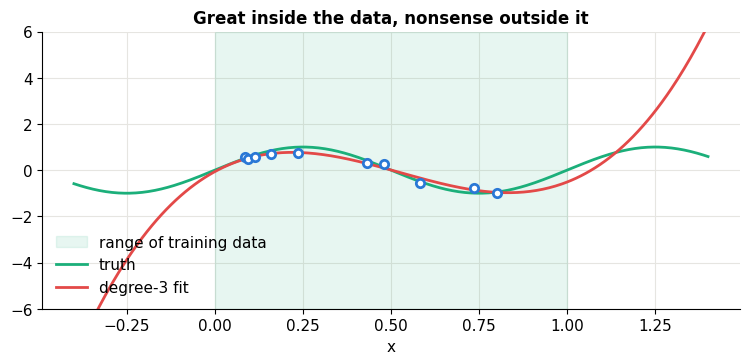

In [22]:
th3_ = np.linalg.lstsq(poly(xtr_s, 3), ytr_s, rcond=None)[0]
xw = np.linspace(-0.4, 1.4, 400)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.axvspan(0, 1, color=C["aqua"], alpha=0.1, label="range of training data")
ax.plot(xw, np.sin(2 * np.pi * xw), color=C["aqua"], lw=2, label="truth")
ax.plot(xw, poly(xw, 3) @ th3_, color=C["red"], lw=2, label="degree-3 fit")
ax.scatter(xtr_s, ytr_s, s=36, facecolor="white", edgecolor=C["blue"], lw=2, zorder=3)
ax.set(ylim=(-6, 6), xlabel="x", title="Great inside the data, nonsense outside it"); ax.legend(loc="lower left")
plt.show()

### Outliers

Squared error punishes a residual of 10 a hundred times more than a residual of 1, so a few wild points can drag the whole fit. Notebook 02 (section 11) showed the remedy (a different likelihood: Laplace noise → absolute error, or the **Huber** loss in between). Always **plot your data** and your residuals before trusting a fit.

### Correlated features (multicollinearity)

Section 9 showed correlated features inflate variance. Here's the extreme case: two features that are almost copies of each other. The individual coefficients become meaningless and unstable, while the **predictions** stay fine.

In [23]:
def collinear_fit(noise=0.01, seed=0):
    r_ = np.random.default_rng(seed)
    a = r_.normal(size=80)
    b = a + noise * r_.normal(size=80)            # b is a near-copy of a
    yy_ = 3 * a + r_.normal(0, 0.5, 80)            # only a truly matters
    Xm = np.column_stack([np.ones(80), a, b])
    return fit_normal_equation(Xm, yy_), fit_ridge(Xm, yy_, 0.05), Xm, yy_

print("Same data-generating process, 5 different random samples (true θ_a = 3, θ_b = 0):\n")
print(f"{'sample':>6} | {'OLS θ_a':>9} {'OLS θ_b':>9} {'θ_a+θ_b':>8} | {'ridge θ_a':>9} {'ridge θ_b':>9}")
for s in range(5):
    t_ols, t_r, *_ = collinear_fit(seed=s)
    print(f"{s:>6} | {t_ols[1]:9.2f} {t_ols[2]:9.2f} {t_ols[1]+t_ols[2]:8.2f} | {t_r[1]:9.2f} {t_r[2]:9.2f}")

Same data-generating process, 5 different random samples (true θ_a = 3, θ_b = 0):

sample |   OLS θ_a   OLS θ_b  θ_a+θ_b | ridge θ_a ridge θ_b
     0 |      4.99     -2.08     2.91 |      1.42      1.41
     1 |     -0.95      3.86     2.90 |      1.40      1.40
     2 |      3.73     -0.64     3.09 |      1.51      1.51
     3 |      3.68     -0.59     3.09 |      1.51      1.51
     4 |      6.01     -3.03     2.98 |      1.46      1.45


Ordinary least squares swings between samples (5.0 and −2.1 in one, −1.0 and 3.9 in the next; the true values are 3 and 0), yet the **sum** $\theta_a + \theta_b$ always lands near 3, so predictions barely change. The data simply can't tell the two features apart. Ridge resolves the ambiguity by splitting the weight evenly, about 1.45 each, every time: far more stable, slightly shrunk (the sum is a bit under 3: that's ridge's bias). Lasso, in notebook 07, would instead pick one of the two.

---
## 11. Summary

| Idea | Formula | Why it matters |
|---|---|---|
| Model | $y = \theta^\top x + \epsilon,\ \epsilon \sim \mathcal{N}(0,\sigma^2)$ | a probabilistic story about the data |
| Loss (MLE) | $\frac1m\|y - X\theta\|^2$ | Gaussian noise ⇒ squared error |
| Normal equation | $X^\top X\hat\theta = X^\top y$ | exact solution; residuals ⟂ features |
| Geometry | $\hat y = Hy$, projection onto col($X$) | adding features never hurts *training* error |
| GD / SGD | $\theta \mathrel{+}= \eta\frac2m X^\top(y - X\theta)$ | scales to huge $m$ and $d$; standardize first |
| Basis functions | $\hat y = \theta^\top\phi(x)$ | nonlinear curves, still linear regression |
| Ridge (MAP) | $(X^\top X + \lambda m I)^{-1}X^\top y$ | shrinks coefficients; always invertible |
| Uncertainty | $\text{Cov}(\hat\theta) = \sigma^2(X^\top X)^{-1}$ | correlated features ⇒ unstable coefficients |

The pattern to remember is CX 4240's three-step pipeline, which every model in Part 1 follows: **probabilistic model → loss via MLE/MAP → optimizer.** Notebook 08 runs the same pipeline with a Bernoulli likelihood and gets logistic regression.

### ✏️ Exercises

1. Show that with only an intercept ($X$ = a column of ones), the normal equation gives $\hat\theta_0 = \bar y$. What does that say about the "baseline" model in the $R^2$ formula?
2. Prove that the hat matrix satisfies $H^2 = H$ and $H^\top = H$. What are its eigenvalues? *(Hint: a projection either keeps a vector or kills it.)*
3. In the polynomial slider, find the smallest number of training points for which degree 9 no longer overfits badly. Relate it to the number of parameters.
4. Fit a ridge regression on the diabetes data and choose $\lambda$ using a **validation split** carved out of the training set (not the test set). Does it beat plain least squares on the test set?
5. Replace the Gaussian basis functions with **sigmoids**, $\phi_j(x) = \sigma((x - c_j)/s)$. Compare the fits. (This is a one-hidden-layer neural network whose hidden layer is frozen.)
6. Implement SGD on the diabetes data with a decaying learning rate $\eta_t = \eta_0/(1 + t/100)$. Plot its test $R^2$ over time against the normal-equation solution.

### References

- CX 4240 Lecture 2 (Linear Algebra Revisit: apartment hunting, LMS), Lecture 4 (GD/SGD for LMS), Lecture 6 (Linear Regression: MLE, normal equation, geometric interpretation, polynomial regression, MAP/ridge).
- ISYE 4600 HW1 (housing-price regression), W5 (ridge), W6 (polynomial regression and ill-conditioning).
- C. Bishop, *Pattern Recognition and Machine Learning*, Sections 1.1 (the sine example) and 3.1–3.3.
- T. Hastie, R. Tibshirani & J. Friedman, *The Elements of Statistical Learning*, Sections 3.1–3.4.
- B. Efron & T. Hastie, *Computer Age Statistical Inference*, Chapter 7 (James–Stein and ridge).
- Diabetes data: B. Efron et al., *Least Angle Regression*, Annals of Statistics (2004).

**Next → [06 · Bias–Variance & Cross-Validation](https://colab.research.google.com/github/shan4949/ml-visualized/blob/main/notebooks/06_bias_variance_cv.ipynb)**